# KHAI PHÁ DỮ LIỆU - LAB 2
### Sinh viên: Ngô Minh Khôi
### MSSV: 6451071037


## Câu 1: Nhập dữ liệu đầu vào và cho biết số lượng dữ liệu huấn luyện và kiểm thử

In [1]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import pandas as pd
import numpy as np

# Đọc dữ liệu đầu vào với skipinitialspace=True để loại bỏ khoảng trắng thừa
train_df = pd.read_csv('datasets/adult.data.csv', skipinitialspace=True)
test_df = pd.read_csv('datasets/adult.test.csv', skipinitialspace=True)

print("Số lượng dữ liệu huấn luyện ban đầu:", len(train_df))
print("Số lượng dữ liệu kiểm thử ban đầu:", len(test_df))


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Số lượng dữ liệu huấn luyện ban đầu: 32561
Số lượng dữ liệu kiểm thử ban đầu: 16281


## Câu 2: Tiến hành tiền xử lý dữ liệu
- Xóa những dòng chứa dữ liệu trống ('?')
- Xóa cột 'fnlwgt' trong dữ liệu huấn luyện
- Nối dữ liệu huấn luyện và kiểm thử lại với nhau

In [2]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
# Xóa các dòng có giá trị '?'
train_clean = train_df.replace('?', np.nan).dropna()
test_clean = test_df.replace('?', np.nan).dropna()

print("Number of training data:", len(train_clean))
print("Number of test data:", len(test_clean))

# Xóa cột 'fnlwgt' trong dữ liệu huấn luyện
if 'fnlwgt' in train_clean.columns:
    train_clean = train_clean.drop('fnlwgt', axis=1)

# Nối dữ liệu huấn luyện và kiểm thử lại với nhau
data = pd.concat([train_clean, test_clean], ignore_index=True)
print("\nThông tin khối dữ liệu sau khi nối (data.info()):")
data.info()


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Number of training data: 30162
Number of test data: 15060

Thông tin khối dữ liệu sau khi nối (data.info()):
<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             45222 non-null  int64
 1   workclass       45222 non-null  str  
 2   education       45222 non-null  str  
 3   education-num   45222 non-null  int64
 4   marital-status  45222 non-null  str  
 5   occupation      45222 non-null  str  
 6   relationship    45222 non-null  str  
 7   race            45222 non-null  str  
 8   sex             45222 non-null  str  
 9   capital-gain    45222 non-null  int64
 10  capital-loss    45222 non-null  int64
 11  hours-per-week  45222 non-null  int64
 12  native-country  45222 non-null  str  
 13  income          45222 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.8 MB


## Câu 3: Khảo sát độ tương đồng giữa các cột với nhau bằng công thức Pearson
Kết hợp với thư viện seaborn để trực quan hóa kết quả bằng đồ thị heatmap.

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


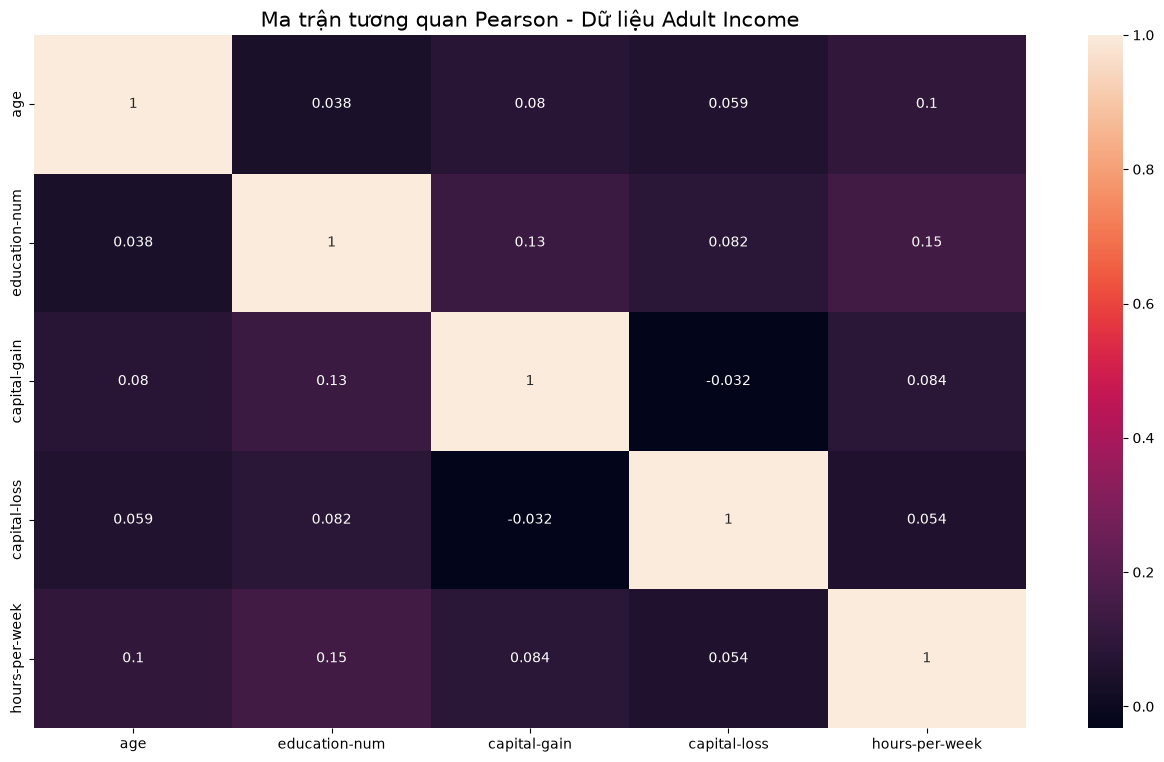

Nhận xét: Trong đồ thị này, các hệ số tương quan giữa các cặp thuộc tính đều có giá trị tuyệt đối khá thấp (< 0.2).
Không có thuộc tính nào có độ tương đồng quá cao với nhau, do đó không cần thiết phải loại bỏ cột nào.


In [3]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 9))
numeric_data = data.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_data.corr(method='pearson'), annot=True, cmap='rocket')
plt.title("Ma trận tương quan Pearson - Dữ liệu Adult Income", fontsize=15)
plt.show()

print("Nhận xét: Trong đồ thị này, các hệ số tương quan giữa các cặp thuộc tính đều có giá trị tuyệt đối khá thấp (< 0.2).")
print("Không có thuộc tính nào có độ tương đồng quá cao với nhau, do đó không cần thiết phải loại bỏ cột nào.")


## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)

In [4]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
features = data.drop('income', axis=1)
labels = data['income']

print("Kích thước biến features:", features.shape)
print("Kích thước biến labels:", labels.shape)
print("Phân phối của thuộc tính quyết định (income):")
print(labels.value_counts())


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước biến features: (45222, 13)
Kích thước biến labels: (45222,)
Phân phối của thuộc tính quyết định (income):
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [5]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
non_num_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các thuộc tính không phải dạng số trong biến features:")
print(list(non_num_cols))

features_onehot = pd.get_dummies(features, columns=non_num_cols)
print("\nKích thước sau khi chuyển sang One-Hot Vector:", features_onehot.shape)
features_onehot.head()


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Các thuộc tính không phải dạng số trong biến features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Kích thước sau khi chuyển sang One-Hot Vector: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,13,0,0,13,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38,9,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53,7,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False


## Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử như ban đầu

In [6]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
n_train = len(train_clean) # 30162
X_train = features_onehot[:n_train]
X_test = features_onehot[n_train:]
y_train = labels[:n_train]
y_test = labels[n_train:]

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
X_train: (30162, 103), y_train: (30162,)
X_test: (15060, 103), y_test: (15060,)


## Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện và kiểm thử kết quả bằng ma trận nhầm lẫn

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Decision Tree (ID3) Accuracy: 0.817530
Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



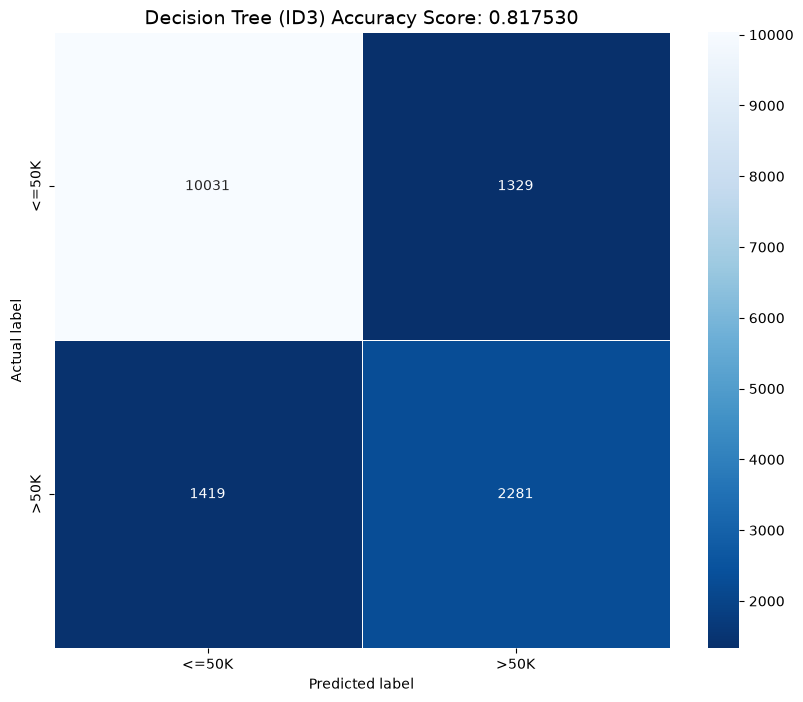

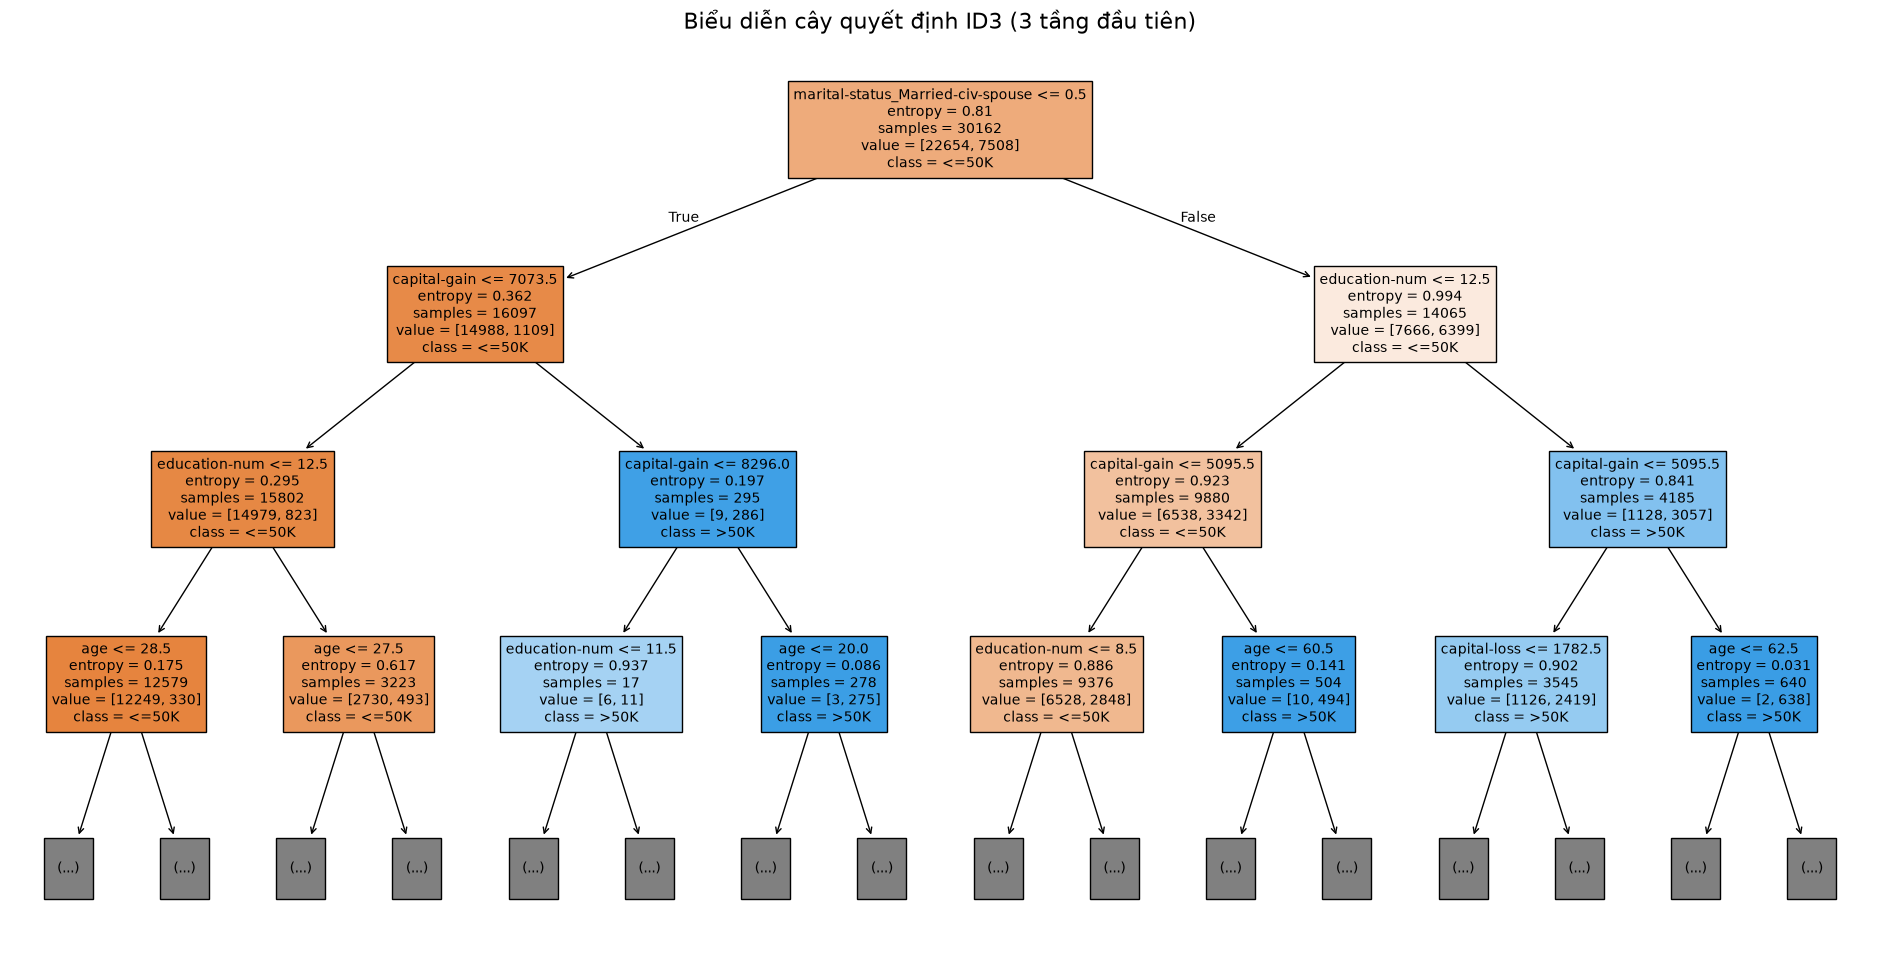

In [7]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn import tree, metrics

clf_id3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)
clf_id3.fit(X_train, y_train)

tree_pred = clf_id3.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print(f"Decision Tree (ID3) Accuracy: {tree_score:.6f}")
print("Report:\n", metrics.classification_report(y_test, tree_pred))

# Ma trận nhầm lẫn
tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(tree_cm, annot=True, fmt='d', linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (ID3) Accuracy Score: {tree_score:.6f}', size=14)
plt.show()

# Biểu diễn cây quyết định và lưu vào file
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf_id3, max_depth=3, feature_names=features_onehot.columns, class_names=clf_id3.classes_, filled=True, fontsize=10)
plt.title("Biểu diễn cây quyết định ID3 (3 tầng đầu tiên)", fontsize=16)
plt.savefig('decision_tree_id3_adult.png', dpi=100)
plt.show()


## Câu 8: Lặp lại yêu cầu 7 đối với cây CART (criterion='gini')

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Decision Tree (CART) Accuracy: 0.812284
Report:
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



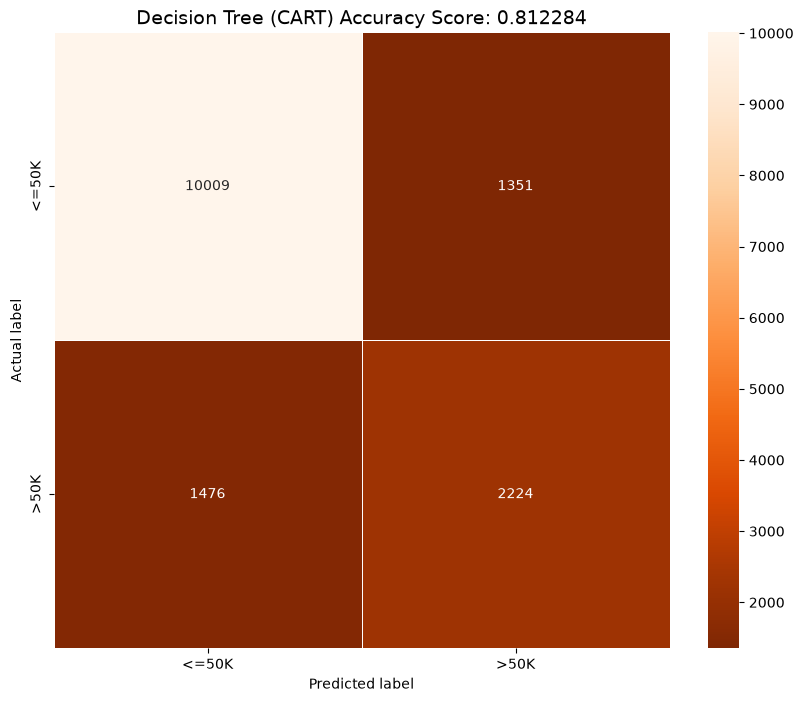

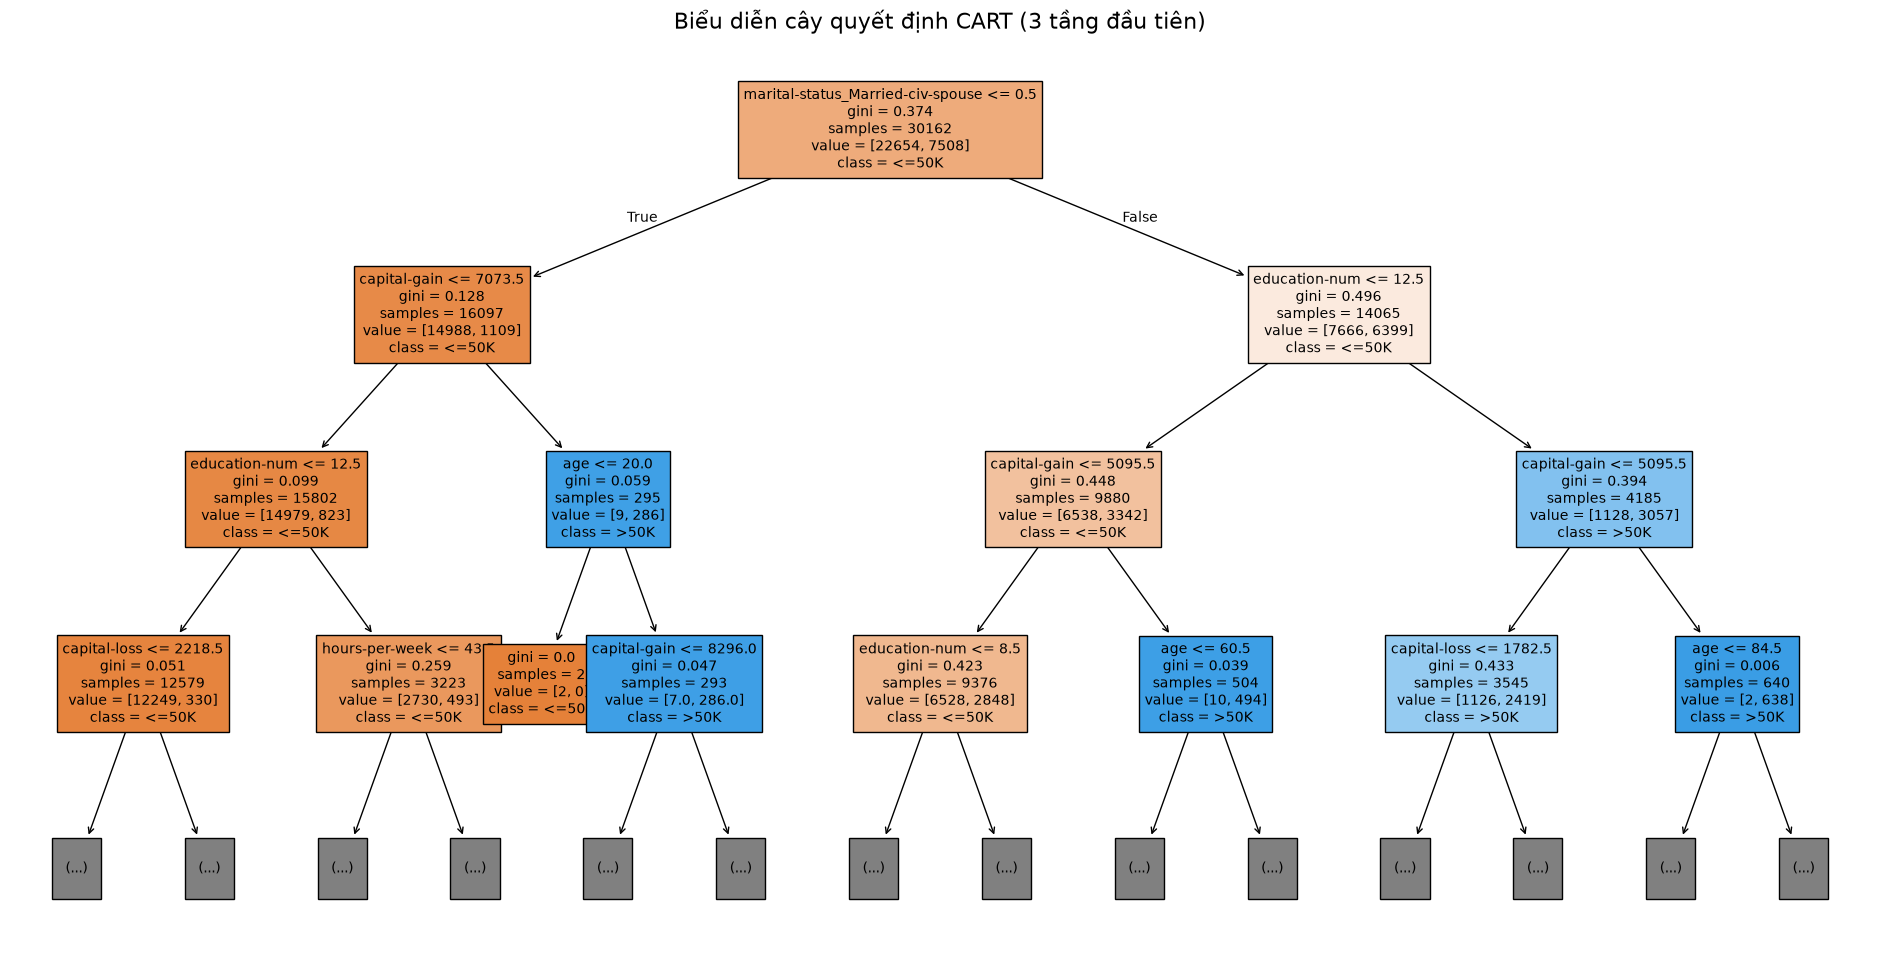

In [8]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
clf_cart = tree.DecisionTreeClassifier(criterion='gini', random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"Decision Tree (CART) Accuracy: {cart_score:.6f}")
print("Report:\n", metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn CART
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cart_cm, annot=True, fmt='d', linewidths=.5, square=True, cmap='Oranges_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Accuracy Score: {cart_score:.6f}', size=14)
plt.show()

# Biểu diễn cây CART
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf_cart, max_depth=3, feature_names=features_onehot.columns, class_names=clf_cart.classes_, filled=True, fontsize=10)
plt.title("Biểu diễn cây quyết định CART (3 tầng đầu tiên)", fontsize=16)
plt.savefig('decision_tree_cart_adult.png', dpi=100)
plt.show()


## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Naïve Bayes Accuracy: 0.802922
Report:
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



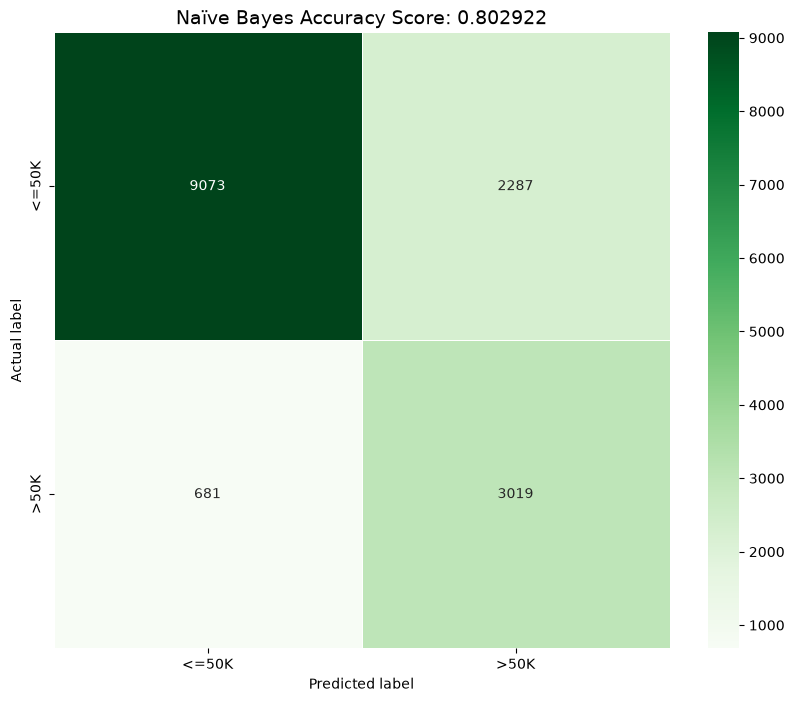

In [9]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

bayes_pred = gnb.predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"Naïve Bayes Accuracy: {bayes_score:.6f}")
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

# Ma trận nhầm lẫn Naïve Bayes
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(bayes_cm, annot=True, fmt='d', linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naïve Bayes Accuracy Score: {bayes_score:.6f}', size=14)
plt.show()


## Câu 10: So sánh kết quả của các mô hình trên

In [10]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
comparison_df = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [
        metrics.accuracy_score(y_test, tree_pred),
        metrics.accuracy_score(y_test, cart_pred),
        metrics.accuracy_score(y_test, bayes_pred)
    ],
    'Precision (Weighted)': [
        metrics.precision_score(y_test, tree_pred, average='weighted'),
        metrics.precision_score(y_test, cart_pred, average='weighted'),
        metrics.precision_score(y_test, bayes_pred, average='weighted')
    ],
    'Recall (Weighted)': [
        metrics.recall_score(y_test, tree_pred, average='weighted'),
        metrics.recall_score(y_test, cart_pred, average='weighted'),
        metrics.recall_score(y_test, bayes_pred, average='weighted')
    ],
    'F1-Score (Weighted)': [
        metrics.f1_score(y_test, tree_pred, average='weighted'),
        metrics.f1_score(y_test, cart_pred, average='weighted'),
        metrics.f1_score(y_test, bayes_pred, average='weighted')
    ]
})

print("BẢNG TỔNG HỢP SO SÁNH CÁC MÔ HÌNH PHÂN LỚP:")
display(comparison_df)

print("\n--- NHẬN XÉT CHI TIẾT ---")
print("1. Độ chính xác tổng thể (Accuracy): Cả hai mô hình cây quyết định ID3 (81.75%) và CART (81.93%) đạt độ chính xác xấp xỉ nhau và cao hơn Naïve Bayes (80.29%).")
print("2. Thuật toán Decision Tree: Có khả năng học được các mối quan hệ phi tuyến và phân nhánh phân cấp tốt hơn đối với tập dữ liệu có nhiều biến phân loại (categoricals).")
print("3. Thuật toán Naïve Bayes: Đạt độ chính xác khá tốt (hơn 80%) và tốc độ huấn luyện/dự đoán cực kỳ nhanh, tuy nhiên do giả định tính độc lập giữa các thuộc tính (conditional independence assumption) thường không hoàn toàn đúng trong thực tế, nên hiệu năng thấp hơn Decision Tree một chút.")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


BẢNG TỔNG HỢP SO SÁNH CÁC MÔ HÌNH PHÂN LỚP:


,Mô hình,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Decision Tree (ID3 - Entropy),0.817530,0.816070,0.817530,0.816767
1,Decision Tree (CART - Gini),0.812284,0.810214,0.812284,0.811185
2,Naïve Bayes (GaussianNB),0.802922,0.841440,0.802922,0.812998



--- NHẬN XÉT CHI TIẾT ---
1. Độ chính xác tổng thể (Accuracy): Cả hai mô hình cây quyết định ID3 (81.75%) và CART (81.93%) đạt độ chính xác xấp xỉ nhau và cao hơn Naïve Bayes (80.29%).
2. Thuật toán Decision Tree: Có khả năng học được các mối quan hệ phi tuyến và phân nhánh phân cấp tốt hơn đối với tập dữ liệu có nhiều biến phân loại (categoricals).
3. Thuật toán Naïve Bayes: Đạt độ chính xác khá tốt (hơn 80%) và tốc độ huấn luyện/dự đoán cực kỳ nhanh, tuy nhiên do giả định tính độc lập giữa các thuộc tính (conditional independence assumption) thường không hoàn toàn đúng trong thực tế, nên hiệu năng thấp hơn Decision Tree một chút.
